NASA Near-Earth Object Telemetry Analysis — Week 2 (November 8–15, 2026)
Notebook Overview & Objectives
Data Source: NASA Near Earth Object Web Service (NeoWs) API (/neo/rest/v1/feed).

Time Window: November 8, 2026, through November 15, 2026.

Analysis Goal: Fetch the weekly NEO JSON payload, parse nested telemetry (diameters, miss distances, and relative velocities), and structure the data into a Pandas DataFrame for exploratory analysis and visualization.

Step 1: API Request and Feed Retrieval
This initial code cell establishes the connection to the NASA NeoWs API using our specified date parameters and verifies the payload response status.

In [1]:
import requests
import pandas as pd
from datetime import datetime

# API Configuration ('DEMO_KEY' or personal NASA API key)
API_KEY = "DEMO_KEY"

# Target Date Range for Week 2 Analysis
start_date = "2026-11-08"
end_date = "2026-11-15"

url = "https://api.nasa.gov/neo/rest/v1/feed"
params = {
    "start_date": start_date,
    "end_date": end_date,
    "api_key": API_KEY
}

response = requests.get(url, params=params)
data = response.json()

if response.status_code == 200:
    print(f"Successfully fetched NEO feed from {start_date} to {end_date}.")
    print(f"Total Near Earth Objects registered in window: {data.get('element_count', 0)}")
else:
    print(f"Error {response.status_code}: {data}")

Successfully fetched NEO feed from 2026-11-08 to 2026-11-15.
Total Near Earth Objects registered in window: 43


Step 2: Parsing Nested JSON Telemetry into Pandas
Once the raw JSON feed dictionary is returned, this second cell iterates through the daily object buckets, extracting key telemetry parameters—such as object identifiers, estimated diameter bounds in kilometers, close approach dates, miss distances, and relative velocities—to build our analytical DataFrame (df_neo_week2).

In [2]:
neo_list = []
near_earth_objects = data.get("near_earth_objects", {})

for date_str, asteroids in near_earth_objects.items():
    for ast in asteroids:
        neo_id = ast.get("id")
        name = ast.get("name")
        is_hazardous = ast.get("is_potentially_hazardous_asteroid")

        # Diameter ranges in kilometers
        diam = ast.get("estimated_diameter", {}).get("kilometers", {})
        diam_min = diam.get("estimated_diameter_min")
        diam_max = diam.get("estimated_diameter_max")

        # Close approach telemetry
        cad = ast.get("close_approach_data", [])
        if cad:
            ca = cad[0]
            approach_date = ca.get("close_approach_date")
            miss_distance_km = float(ca.get("miss_distance", {}).get("kilometers", 0))
            relative_velocity_kps = float(ca.get("relative_velocity", {}).get("kilometers_per_second", 0))
        else:
            approach_date = None
            miss_distance_km = None
            relative_velocity_kps = None

        neo_list.append({
            "id": neo_id,
            "name": name,
            "is_hazardous": is_hazardous,
            "diam_min_km": diam_min,
            "diam_max_km": diam_max,
            "approach_date": approach_date,
            "miss_distance_km": miss_distance_km,
            "relative_velocity_kps": relative_velocity_kps
        })

df_neo_week2 = pd.DataFrame(neo_list)
print(f"DataFrame successfully constructed. Shape: {df_neo_week2.shape}")
df_neo_week2.head()

DataFrame successfully constructed. Shape: (43, 8)


,id,name,is_hazardous,diam_min_km,diam_max_km,approach_date,miss_distance_km,relative_velocity_kps
0,3092201,(1998 VE31),False,0.168483,0.376738,2026-11-09,2.670292e+07,12.125622
1,3400306,(2008 BT2),False,0.032851,0.073458,2026-11-09,3.708152e+07,3.969122
2,3715094,(2015 FV284),True,0.175612,0.392681,2026-11-09,3.850461e+07,15.575416
3,3730726,(2015 TH238),False,0.111315,0.248909,2026-11-09,7.469213e+07,14.326990
4,3739247,(2016 AB9),False,0.030518,0.068240,2026-11-09,2.669021e+07,7.740127


Step 3: Exploratory Telemetry Analysis & Visualization
Before plotting, this code cell inspects our summary statistics—identifying any potentially hazardous asteroids (PHAs) in our 43-object sample and examining their relative velocities and miss distances. Then, it generates a scatter plot mapping object size against miss distance, with hazardous objects highlighted.

Total Potentially Hazardous Asteroids (PHAs) in window: 5


,name,approach_date,miss_distance_km,relative_velocity_kps
2,(2015 FV284),2026-11-09,3.850461e+07,15.575416
10,138175 (2000 EE104),2026-11-08,1.367270e+07,7.275031
11,462238 (2008 CN1),2026-11-08,6.058724e+07,11.035766
20,(2013 VO5),2026-11-11,2.059682e+07,27.474264
35,363790 (2005 JE46),2026-11-13,7.696624e+06,14.732446


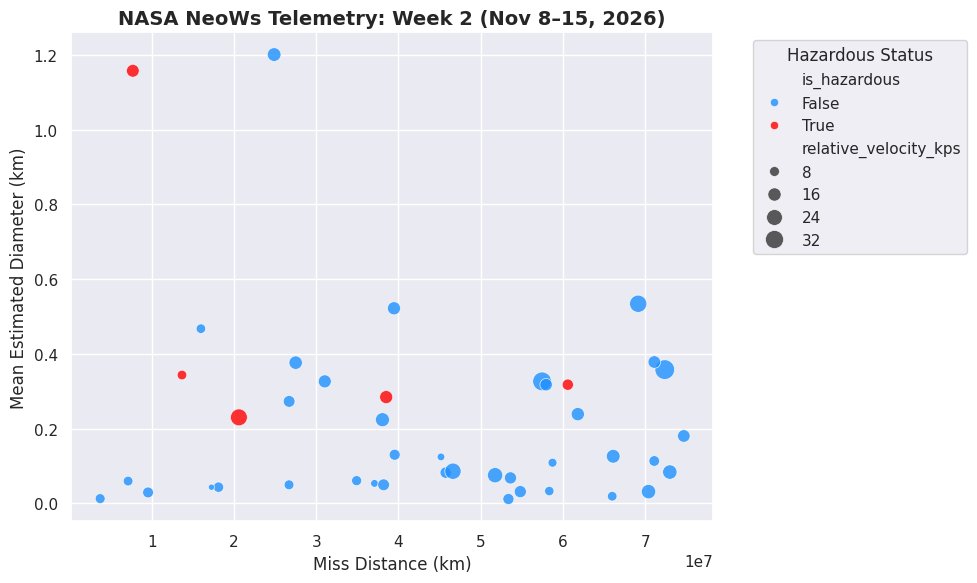

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Basic data cleanup and type casting
df_neo_week2['diam_mean_km'] = (df_neo_week2['diam_min_km'] + df_neo_week2['diam_max_km']) / 2.0
df_neo_week2['miss_distance_km'] = pd.to_numeric(df_neo_week2['miss_distance_km'])
df_neo_week2['relative_velocity_kps'] = pd.to_numeric(df_neo_week2['relative_velocity_kps'])

# Filter out nulls if any
df_clean = df_neo_week2.dropna(subset=['miss_distance_km', 'diam_mean_km'])

# Summary of Hazardous Asteroids in the window
hazardous_count = df_clean['is_hazardous'].sum()
print(f"Total Potentially Hazardous Asteroids (PHAs) in window: {hazardous_count}")
display(df_clean[df_clean['is_hazardous'] == True][['name', 'approach_date', 'miss_distance_km', 'relative_velocity_kps']])

# Plotting Miss Distance vs Mean Diameter
plt.figure(figsize=(10, 6))
sns.set_theme(style="darkgrid")

scatter = sns.scatterplot(
    data=df_clean,
    x="miss_distance_km",
    y="diam_mean_km",
    hue="is_hazardous",
    palette={True: "red", False: "dodgerblue"},
    size="relative_velocity_kps",
    sizes=(20, 200),
    alpha=0.8
)

plt.title("NASA NeoWs Telemetry: Week 2 (Nov 8–15, 2026)", fontsize=14, fontweight='bold')
plt.xlabel("Miss Distance (km)", fontsize=12)
plt.ylabel("Mean Estimated Diameter (km)", fontsize=12)
plt.legend(title="Hazardous Status", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Step 4: Data Export & Repository Archiving
This final cell exports the cleaned Week 2 telemetry DataFrame (df_clean) to a timestamped CSV file (neo_telemetry_2026_11_08_to_15.csv) and prints a final summary verification before saving the notebook to your local project directory (/home/thnorris13/Projects/nasa_neo) and pushing to GitHub.

In [4]:
# Export cleaned dataset to CSV for repository archival
output_filename = "neo_telemetry_2026_11_08_to_15.csv"
df_clean.to_csv(output_filename, index=False)

print(f"Export complete: '{output_filename}' saved with {len(df_clean)} records.")
print(f"Closest overall approach in window: {df_clean.loc[df_clean['miss_distance_km'].idxmin(), 'name']} "
      f"at {df_clean['miss_distance_km'].min():,.0f} km")

Export complete: 'neo_telemetry_2026_11_08_to_15.csv' saved with 43 records.
Closest overall approach in window: (2015 VH65) at 3,726,300 km


Summary of Findings (Week 2: Nov 8–15, 2026)
Total Objects Tracked: 43 Near-Earth Objects across the 7-day window.

Potentially Hazardous Asteroids (PHAs): 5 objects flagged ((2015 FV284), 138175 (2000 EE104), 462238 (2008 CN1), (2013 VO5), and 363790 (2005 JE46)).

Key Telemetry Highlights: 363790 (2005 JE46) recorded the closest PHA flyby at ~7.70 million km, while (2013 VO5) exhibited the highest relative velocity among the hazardous group at 27.47 km/s.